# Check Spectra Extraction Quality

Check the extraction performance with and without sky subtraction.

## 1. Initialisation

In [6]:
from path import Path
from astropy.io import fits
from astropy.table import Table
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pypeit.specutils import Spectrum, SpectrumList

np.set_printoptions(
    precision=4,
    suppress=True,
    linewidth=200
)

### 1.1 Functions

In [21]:
def create_folders(folders):
    spec1d = {}
    spec2d = {}

    for reduction, folder in folders.items():

        fits_files = sorted(folder.glob("*.fits"))

        for file in fits_files:

            if "spec1d" in file.name.lower():
                collection = spec1d
                spectra = SpectrumList.read(file, strict=False)

            elif "spec2d" in file.name.lower():
                collection = spec2d
                spectra = None

            else:
                continue

            # Extract identifier from filename
            match = re.search(r'0005(\d{3})(\d{3})', file.name)

            file_id = (
                f"img{int(match.group(2))}"
                if match else file.stem
            )

            with fits.open(file) as hdul:

                # Collect extensions containing data
                slit_hdus = []

                for hdu in hdul[1:]:

                    if hdu.data is None:
                        continue

                    match_slit = re.search(
                        r'SPAT\d+-SLIT(\d+)-DET\d+', hdu.name
                    )

                    slit_name = (
                        f"S{int(match_slit.group(1))}"
                        if match_slit else hdu.name
                    )

                    slit_hdus.append((slit_name, hdu))

                # Check correspondence between FITS extensions and spectra
                if spectra is not None and len(spectra) != len(slit_hdus):
                    raise ValueError(
                        f"{file.name}: found {len(slit_hdus)} slit extensions "
                        f"but {len(spectra)} Spectrum objects."
                    )

                file_data = {
                    "filename": file.name,
                    "primary_header": hdul[0].header.copy(),
                    "slits": {}
                }

                for i, (slit_name, hdu) in enumerate(slit_hdus):

                    slit_data = {
                        "data": hdu.data.copy(),
                        "header": hdu.header.copy()
                    }

                    # Add extracted Spectrum object for spec1d
                    if spectra is not None:
                        slit_data["spectrum"] = spectra[i]

                    file_data["slits"][slit_name] = slit_data

                collection.setdefault(reduction, {})[file_id] = file_data

    return spec1d, spec2d

def load_spectra(spec, img1, reduction1, slit1,
                 img2=None, reduction2=None, slit2=None):

    img2, reduction2, slit2 = (
        img2 or img1,
        reduction2 or reduction1,
        slit2 or slit1
    )

    def extract(img, reduction, slit):
        return spec[reduction][img]["slits"][slit]["spectrum"]

    return (
        extract(img1, reduction1, slit1),
        extract(img2, reduction2, slit2)
    )


### 1.2 Paths

In [22]:
AGOS_SUB_PATH = Path('C:\\Users\\noah.bensoussan\\GTC\\RD_GTC_23AGOS\\gtc_osiris_plus_A\\Science')
AGOS_NO_SUB_PATH = Path('C:\\Users\\noah.bensoussan\\GTC\\RD_GTC_23AGOS\\gtc_osiris_plus_A_no_sub\\Science')

AMEX_SUB_PATH = Path('C:\\Users\\noah.bensoussan\\GTC\\RD_58_26AMEX\\gtc_osiris_plus_A\\Science')
AMEX_NO_SUB_PATH = Path('C:\\Users\\noah.bensoussan\\GTC\\RD_58_26AMEX\\gtc_osiris_plus_A_no_sub\\Science')


folders = {
    "sub": AGOS_SUB_PATH,
    "no_sub": AGOS_NO_SUB_PATH
}

spec1d_agos, spec2d_agos = create_folders(folders)
spec1d_amex, spec2d_amex = create_folders({"sub": AMEX_SUB_PATH, "no_sub": AMEX_NO_SUB_PATH})

 [WARNING] - pypeit_loaders.py:pypeit_spec1d_loader:207 - Ignoring 62 masked pixels.
 [WARNING] - pypeit_loaders.py:pypeit_spec1d_loader:207 - Ignoring 106 masked pixels.
 [WARNING] - pypeit_loaders.py:pypeit_spec1d_loader:207 - Ignoring 174 masked pixels.
 [WARNING] - pypeit_loaders.py:pypeit_spec1d_loader:207 - Ignoring 59 masked pixels.
 [WARNING] - pypeit_loaders.py:pypeit_spec1d_loader:207 - Ignoring 173 masked pixels.
 [WARNING] - pypeit_loaders.py:pypeit_spec1d_loader:207 - Ignoring 81 masked pixels.
 [WARNING] - pypeit_loaders.py:pypeit_spec1d_loader:207 - Ignoring 593 masked pixels.
 [WARNING] - pypeit_loaders.py:pypeit_spec1d_loader:207 - Ignoring 415 masked pixels.
 [WARNING] - pypeit_loaders.py:_enforce_monotonic_wavelengths:87 - Wavelengths are not monotonically increasing!  Strict was set to False, so measurements after a negative step in wavelength are removed from the constructed spectrum.  BEWARE that this is likely the result of an error in the data reduction!
 [WARNI

ValueError: spec1d_0005255491-20250524-OSIRIS-OsirisMOS-M2_otelo_1_OSIRIS_20250525T000322.593.fits: found 11 slit extensions but 10 Spectrum objects.

## 2. Extraction Statistics

In [12]:
tab = Table(spec1d_agos["sub"]["img491"]["slits"]["S501"]["data"])

In [27]:
spec = SpectrumList.read( AGOS_SUB_PATH / "spec1d_0005255491-20250524-OSIRIS-OsirisMOS-M2_otelo_1_OSIRIS_20250525T000322.593.fits", strict=False)

 [WARNING] - pypeit_loaders.py:pypeit_spec1d_loader:207 - Ignoring 62 masked pixels.
 [WARNING] - pypeit_loaders.py:pypeit_spec1d_loader:207 - Ignoring 106 masked pixels.
 [WARNING] - pypeit_loaders.py:pypeit_spec1d_loader:207 - Ignoring 174 masked pixels.
 [WARNING] - pypeit_loaders.py:pypeit_spec1d_loader:207 - Ignoring 59 masked pixels.
 [WARNING] - pypeit_loaders.py:pypeit_spec1d_loader:207 - Ignoring 173 masked pixels.
 [WARNING] - pypeit_loaders.py:pypeit_spec1d_loader:207 - Ignoring 81 masked pixels.
 [WARNING] - pypeit_loaders.py:pypeit_spec1d_loader:207 - Ignoring 593 masked pixels.
 [WARNING] - pypeit_loaders.py:pypeit_spec1d_loader:207 - Ignoring 415 masked pixels.
 [WARNING] - pypeit_loaders.py:_enforce_monotonic_wavelengths:87 - Wavelengths are not monotonically increasing!  Strict was set to False, so measurements after a negative step in wavelength are removed from the constructed spectrum.  BEWARE that this is likely the result of an error in the data reduction!
 [WARNI

In [18]:
spec


[<Spectrum(flux=[32.52774591001471 ... -137.69123312968296] electron (shape=(1962,), mean=19.74534 electron); spectral_axis=<SpectralAxis 
    (doppler_rest=None
     doppler_convention=doppler_optical)
   [ 4611.4151  4614.1221  4616.7868 ... 11393.2013 11399.1071 11404.5063] Angstrom> (length=1962); uncertainty=StdDevUncertainty)>,
 <Spectrum(flux=[-324.2034365456872 ... 25.73392085403096] electron (shape=(1918,), mean=2728.26615 electron); spectral_axis=<SpectralAxis 
    (doppler_rest=None
     doppler_convention=doppler_optical)
   [4734.3941 4736.2478 4738.165  ... 9858.8976 9861.8804 9864.7575] Angstrom> (length=1918); uncertainty=StdDevUncertainty)>,
 <Spectrum(flux=[14.92955278428101 ... 7890.075206317914] electron (shape=(1850,), mean=-219.29981 electron); spectral_axis=<SpectralAxis 
    (doppler_rest=None
     doppler_convention=doppler_optical)
   [3279.6258 3281.4597 3283.2895 ... 7893.8124 7896.6848 7902.3244] Angstrom> (length=1850); uncertainty=StdDevUncertainty)>,
 <S

AttributeError: 'SpectrumList' object has no attribute 'spectral_axis'

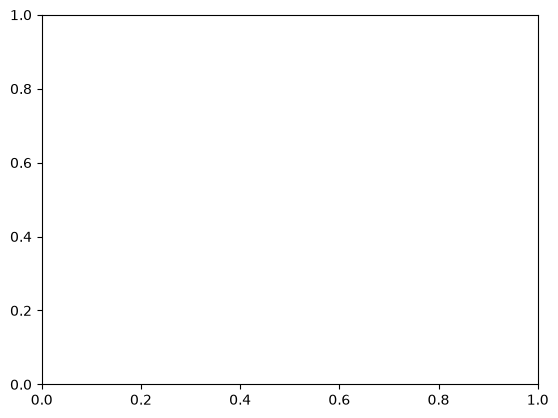

In [10]:
f, ax = plt.subplots()
ax.step(spec.spectral_axis, spec.flux)

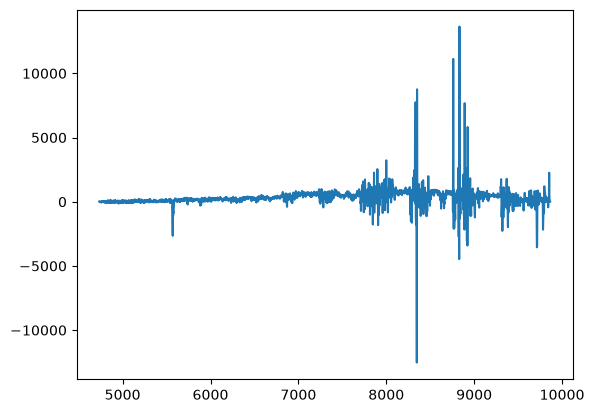

In [19]:
plt.plot(tab["OPT_WAVE"], tab["OPT_COUNTS"])